<a href="https://colab.research.google.com/github/KjelleJ/enkla-ai-experiment/blob/main/AIX_11_chatbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Orderbot till pizzeria
En enkel prototyp som använder ett API (programmeringsinterface) till den stora språkmodellen gemini-3.5-flash-lite. Vår orderbot finns på nivå 6 i följande figur som visar utvecklingen av AI.





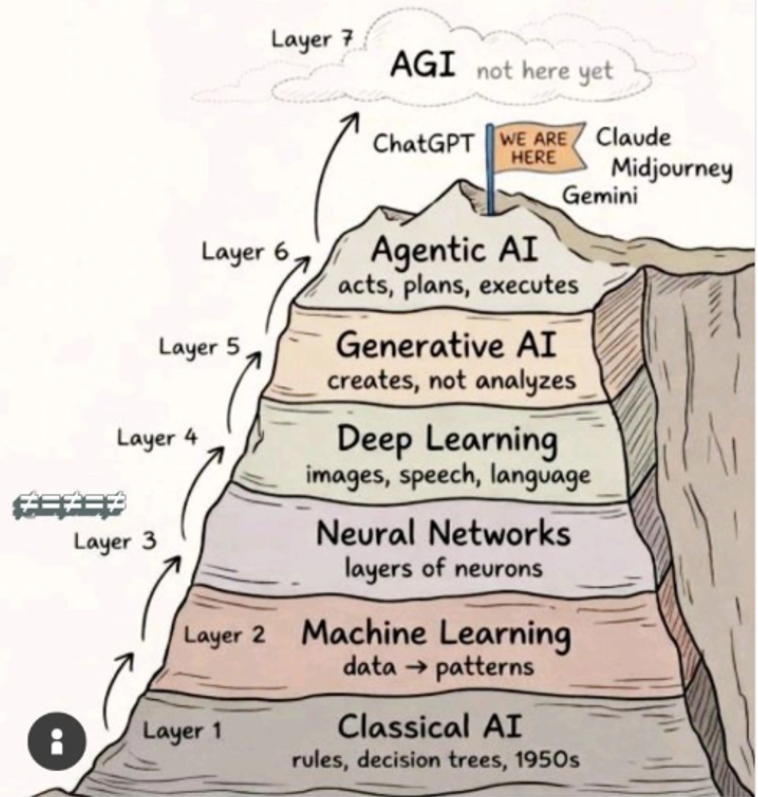

---



För att kunna använda api:et behöver du skapa en kostnadsfri API-nyckel till Gemini enligt följande anvisningar.

### 🔑 Instruktion för elever: Skapa en egen API-nyckel för Gemini

Följ dessa enkla steg för att skapa din egen kostnadsfria API-nyckel så att du kan köra din pizzeria-chatbot:

1. **Gå till Google AI Studio**
   Öppna webbläsaren och gå till [https://aistudio.google.com/](https://aistudio.google.com/).

2. **Logga in**
   Logga in med ditt vanliga Google-konto (t.ex. ditt skolkonto eller privata Gmail-konto).

3. **Skapa nyckeln (Get API Key)**
   * Klicka på den lilla nyckeln **"Get API key"** nere till vänster.
   * Klicka på **"Create API key"**.
   * Om du får välja projekt, välj **"Create API key in new project"**.

4. **Kopiera nyckeln**
   * En lång rad med bokstäver och siffror visas (din unika API-nyckel).
   * Klicka på **"Copy"** för att kopiera den. *Dela aldrig denna nyckel med någon annan!*

5. **Lägg till nyckeln i Google Colab**
   * Gå tillbaka till denna Google Colab-flik.
   * Klicka på **nyckelsymbolen (🔑 Secrets)** i menyn längst till vänster.
   * Klicka på **"Add new secret"**.
   * Under **Name** skriver du: `GOOGLE_API_KEY`
   * Under **Value** klistrar du in din kopierade API-nyckel.
   * Se till att aktivera bocken för **"Notebook access"** så att koden i din notebook kan läsa nyckeln.

Nu är du redo att köra koden och prata med din chatbot!

### 🍕 Skapa en Pizzeria-chatbot med Gemini API

Först installerar vi det officiella Python-SDK:t för Gemini (`google-genai`).

In [ ]:
!pip install google-genai

Nu kan vi hämta din API-nyckel från Colabs hemligheter, initiera klienten och starta en chatt med en **systeminstruktion** som beskriver hur chatboten ska bete sig (t.ex. sälja pizza, visa meny och vara trevlig).

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata

try:
    # Hämtar din API-nyckel från Colabs Secrets manager
    api_key = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=api_key)
    print("Klienten har initierats framgångsrikt!")
except Exception as e:
    print("Fel: Kontrollera att du har lagt till GOOGLE_API_KEY i dina Secrets i Colab.")
    print(e)

Här startar vi en chatt-session där vi skickar med en systeminstruktion och skapar en enkel loop för att prata med boten direkt i Colab.

In [ ]:
system_instruction = """
Du är Mario, en trevlig och hjälpsam chatbot för pizzerian 'Bella Napoli'.
Din uppgift är att ta emot beställningar och svara på frågor om menyn.

Meny:
1. Margherita (Tomatsås, ost) - 95 kr
2. Vesuvio (Tomatsås, ost, skinka) - 105 kr
3. Capricciosa (Tomatsås, ost, skinka, svamp) - 115 kr
4. Rotmos med fläsklägg - 150 kr
Dryck: Läsk (Coca-Cola, Fanta, Sprite) - 25 kr

Håll dina svar korta, trevliga och på svenska. Fråga alltid efter kundens namn
och om de vill hämta eller ha hemkörning när de beställer.
"""

chat = client.chats.create(
    model="gemini-3.5-flash-lite",
    config=types.GenerateContentConfig(
        system_instruction=system_instruction,
        temperature=0.7
    )
)

# Starta en kort testkonversation
response = chat.send_message("Hej! Vad har ni för pizzor?")
print("Bot:", response.text)



---


# En LLM saknar minne - löses med Kontext
Vad som finns är många miljarder med vikter som innehåller all kunskap som modellen har. Men det minnet är statiskt, ändras inte efter träningen.

### Vad är kontext för en LLM?

Inom AI och stora språkmodeller (LLM) syftar **kontext** på den information och bakgrund som modellen har tillgång till vid ett givet tillfälle för att kunna förstå och besvara en användares fråga. Man kan dela upp det i några olika delar:

1. **Systeminstruktion (System Prompt):** De övergripande reglerna som definierar modellens roll, tonfall och begränsningar (t.ex. *"Du är Mario, en trevlig chatbot för Bella Napoli..."*).
2. **Konversationshistorik:** De tidigare meddelandena i chatten. Utan historik som kontext skulle modellen glömma bort vad du sa i förra meningen. En stor nackdel är att historiken blir allt längre så länge sessionen varar.
3. **Kontextfönster (Context Window):** Det maximala antalet ord eller tecken (tokens) som modellen kan läsa och minnas på en och samma gång.

Om du vill köra en interaktiv chatt-loop där du kan skriva fritt i en textruta, kan du köra följande cell:

In [ ]:
# Testa vår orderbot:
# 1. Gör en beställning för avhämtning, fråga vad pizzerian heter, fråga om adressen...
# 2. Gör en beställning för leverans
# 3. Begär ett förslag till en kort AI-kurs

print("Skriv 'avsluta' för att stänga chatten.\n")
while True:
    user_input = input("Du: ")
    if user_input.lower() == 'avsluta':
        print("Chatten avslutad.")
        break

    response = chat.send_message(user_input)
    print(f"Bot: {response.text}\n")

#En app för Bella Napoli
---
#####En vanlig användare kan inte köra våran bot via Colab. Vi behöver en app, helst en webbapp som kan köras i webbläsaren. Jag bad Gemini att göra en sådan app. Vi vill inte exponera vår API-nyckel för en användare av appen. Därför kommunicerar själva appen (index.html) med en PHP-proxy (api.php) som innehåller API-nyckeln och kommunicerar med Gemini (vår LLM). api.php laddas aldrig ner till användaren.
OBS! Appen använder en gratisnyckel. Acess kan bli nekad pga hög last när USA vaknar.

Provkör här [kurser.gubboit.se/pizzeria](https://kurser.gubboit.se/pizzeria)

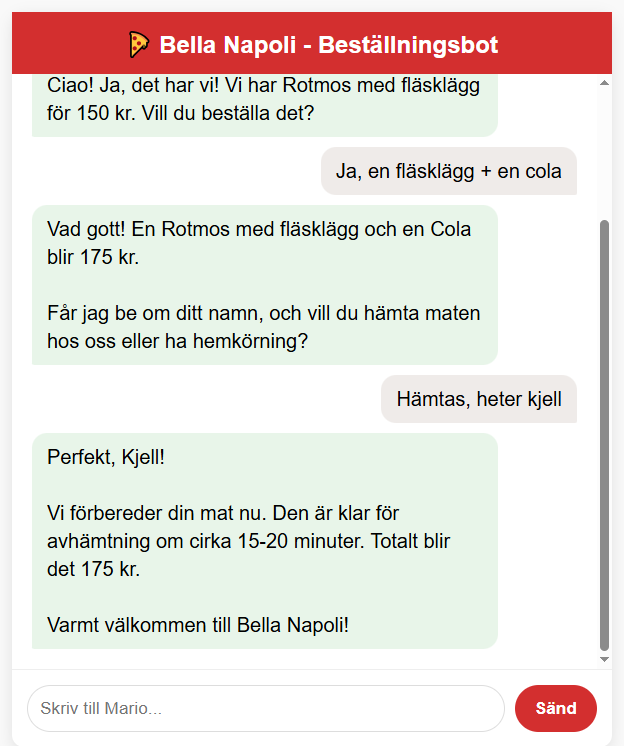
---

---



# Dokument Bot - "Fråga ett dokument"
För att vår dokbot ska kunna läsa dokumentet lägger vi in dokumentet i systemprompten. Vår LLM (gemini-3.5-flash-lite) har ett kontextfönster på 1 miljon tokens (ungefär 500 000 (?) ord). Dokumentet bör förstås vara mindre.

---



In [ ]:
# Vi läser in dokumentet till variabeln "dokument_text"
import urllib.request

# Webb-länk till ett källdokument (en rå textfil är enklast att börja med)
url = "https://www.gutenberg.org/ebooks/21862.txt.utf-8"
try:
    # Hämta innehållet från länken
    with urllib.request.urlopen(url) as response:
        # Läser in texten och avkodar den till UTF-8 (så att å, ä, ö visas korrekt)
        dokument_text = response.read().decode('utf-8')

    print("Dokumentet har hämtats framgångsrikt!")
    print(f"Antal tecken i dokumentet: {len(dokument_text)}")
    print("\nHär är början på dokumentet:")
    print("-" * 40)
    print(dokument_text[:500] + "...") # Visar de första 500 tecknen
    print("-" * 40)

except Exception as e:
    print("Kunde inte hämta dokumentet. Kontrollera länken.")
    print(e)

In [ ]:
# Vi skapar systeminstruktionen där vi bäddar in dokumentet
system_instruction_doc = f"""
Du är Horace, är en pedagogisk och tålmodig dokument-assistent.
Din uppgift är att svara på frågor från en klient. Du får ENDAST svara på frågor
 baserat på informationen i dokumentet nedan. För sådana frågor svara "Det kan jag
 tyvärr inte svara på".
Du ska kunna ge en kort sammanfattning av dokumentet men bara på begäran.

Här är dokumentet du ska använda:
--- DOKUMENT START ---
{dokument_text}
--- DOKUMENT SLUT ---
"""



#Lösning: Fristående frågor utan historik
---

En chat-lösning funkar inte bra pga att hela systemprompten läggs till dialogen (historiken) för varje fråga. I systemprompten finns dokumentet som i vårt fall är en hel bok. Så för första frågan skickas boken in en gång, för andra frågan 2 gånger osv. Då tar kontextfönstret snart slut. Om vi i stället för en chat använder fristående frågor försvinner det problemet.


In [ ]:
import textwrap

# Funktion för att ställa en fristående fråga utan att bygga upp historik
# Svaret formateras automatiskt till max 80 tecken per rad för bättre läsbarhet
def fraga_dokumentet(fraga):
    try:
        response = client.models.generate_content(
            model="gemini-3.5-flash-lite",
            contents=fraga,
            config=types.GenerateContentConfig(
                system_instruction=system_instruction_doc,
                temperature=0.3
            )
        )

        if response.text:
            # Formatera svaret så att rader bryts snyggt vid max 80 tecken
            formatted_text = "\n".join(
                textwrap.fill(line, width=80) if line.strip() else ""
                for line in response.text.split("\n")
            )
            return formatted_text
        else:
            return "(Kunde inte generera ett svar.)"

    except Exception as e:
        return f"(Ett fel uppstod: {e})"


##Interaktiv loop för fristående frågor utan sparad historik.
1. Provkör först vår dokbot.
2. Vår dokbot är ganska begränsad och svarar ofta att information inte finns i dokumentet. Pröva att ta bort instruktionen "Du får ENDAST svara på frågor
 baserat på informationen i dokumentet nedan." i systemprompten.
3. Kör därefter alla celler från cellen för systemprompten.
4. Provkör vår dokbot igen.

In [ ]:
# Interaktiv loop för fristående frågor utan sparad historik
print("Skriv 'avsluta' för att stänga frågestunden.\n")

while True:
    user_input = input("Din fråga till dokumentet: ")
    if user_input.lower() == 'avsluta':
        print("Frågestunden avslutad.")
        break

    # Anropa vår funktion som inte sparar historik och som radbryter vid 80 tecken
    svar = fraga_dokumentet(user_input)
    print(f"\nAssistent:\n{svar}\n")